# 14. Phase Trajectory Practice

**Objective**: Create phase trajectory (state-space trajectory) plots that show how
two variables co-evolve over time.  
Each point represents a year's aggregated value, and arrows connect consecutive years
to show the trajectory direction.

**Reference style**: Similar to Fig. 3c in Yanagi (2015) — TP load vs. red tide occurrence
with year labels and directional arrows.

---
## How to customize
All tuneable parameters are gathered in **Cell 2 (Configuration)**. You can change:
- `X_VAR` / `Y_VAR` — which columns to plot on each axis
- `FILTER_DIVISION` — spatial subset (e.g. `'Osaka Bay'`, `'Harima Nada'`, or `None` for all)
- `FILTER_SEASON` — temporal subset (e.g. `'Summer'`, or `None` for all)
- `YEAR_RANGE` — tuple of (start_year, end_year)
- `LABEL_INTERVAL` — label every Nth year
- Figure aesthetics (colors, sizes, fonts, etc.)

In [1]:
# --- Cell 1: Imports & Path Setup ---
import sys
from pathlib import Path

# Ensure local scripts are importable (works from notebooks/ or notebooks/pipeline/)
project_root = Path("..").resolve()
if str(project_root) not in sys.path:
    sys.path.insert(0, str(project_root))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patheffects as pe
from scripts.paths import ProjectPaths

print("Project Root:", ProjectPaths.PROJECT_ROOT)
print("Data file:", ProjectPaths.MERGED_DATA_FILE)

Project Root: /home/reyha/SIS_Analysis_WSL
Data file: /home/reyha/SIS_Analysis_WSL/data/processed/merged_gdf.feather


In [2]:
# ============================================================
# Cell 2: CONFIGURATION  —  Tweek everything here!
# ============================================================

# --- Data selection ---
X_VAR = 'tn2'            # Column name for x-axis  (e.g. 'tn2', 'tp2', 'cod2', 'do_2')
Y_VAR = 'do_2'           # Column name for y-axis  (e.g. 'do_2', 'chloroph_1', 'cod2')

FILTER_DIVISION = 'Osaka Bay'   # Spatial filter: 'Osaka Bay', 'Harima Nada', None (=all)
FILTER_SEASON   = 'Summer'      # Season filter:  'Summer', 'Winter', 'Spring', 'Autumn', None (=all)
FILTER_SAISUIPOIN = 2           # Sampling depth point: 1=surface, 2=bottom, None=all
YEAR_RANGE = (1981, 2023)       # (start_year, end_year) inclusive
AGG_FUNC = 'mean'               # Aggregation: 'mean', 'median', 'min', 'max'

# --- Year labels ---
LABEL_INTERVAL = 5              # Label every Nth year (1 = every year)
LABEL_FORMAT = "'{:02d}"        # Format string for year labels (e.g. "'{:02d}" -> '81, '85...)
LABEL_FONTSIZE = 9
LABEL_OFFSET = (5, 5)           # (dx, dy) offset in points from the data point

# --- Axis labels (LaTeX supported) ---
X_LABEL = 'TN concentration (mg/L)'
Y_LABEL = 'Bottom DO concentration (mg/L)'
TITLE   = f'Phase Trajectory: {Y_VAR} vs {X_VAR}'
SUBTITLE = f'{FILTER_DIVISION or "All regions"} — {FILTER_SEASON or "All seasons"}'

# --- Figure style ---
FIGSIZE = (8, 6)
DPI = 150
MARKER_SIZE = 50
MARKER_COLOR = '#2c3e50'        # Dark blue-gray
ARROW_COLOR = '#2c3e50'
ARROW_WIDTH = 1.5
ARROW_HEAD_WIDTH = 8
ARROW_HEAD_LENGTH = 6
GRID_ALPHA = 0.3
FONT_FAMILY = 'serif'           # 'serif', 'sans-serif', 'monospace'

# --- Save options ---
SAVE_FIGURE = False
SAVE_PATH = ProjectPaths.FIGURES_DIR / 'phase_trajectory.png'

print("Configuration loaded.")
print(f"  X: {X_VAR}  |  Y: {Y_VAR}")
print(f"  Region: {FILTER_DIVISION}  |  Season: {FILTER_SEASON}")
print(f"  Years: {YEAR_RANGE[0]}–{YEAR_RANGE[1]}")

Configuration loaded.
  X: tn2  |  Y: do_2
  Region: Osaka Bay  |  Season: Summer
  Years: 1981–2023


In [3]:
# --- Cell 3: Load Data ---
df = pd.read_feather(ProjectPaths.MERGED_DATA_FILE)
print(f"Loaded {len(df)} rows, {len(df.columns)} columns")
print(f"Year range in data: {df['year'].min()} – {df['year'].max()}")
print(f"Available divisions: {sorted(df['division'].unique())}")
print(f"Available seasons:   {sorted(df['season'].unique())}")

Loaded 42326 rows, 65 columns
Year range in data: 1981 – 2023
Available divisions: ['Aki Nada', 'Bingo Nada', 'Bisan Seto', 'Bungo Channel', 'Harima Nada', 'Hibiki Nada', 'Hiroshima Bay', 'Hiuchi Nada', 'Iyo Nada', 'Kii Channel', 'Osaka Bay', 'Suo Nada']
Available seasons:   ['Autumn', 'Spring', 'Summer', 'Winter']


In [4]:
# --- Cell 4: Filter & Aggregate ---

# Start with full dataset
filtered = df.copy()

# Apply filters
if FILTER_DIVISION is not None:
    filtered = filtered[filtered['division'] == FILTER_DIVISION]
if FILTER_SEASON is not None:
    filtered = filtered[filtered['season'] == FILTER_SEASON]
if FILTER_SAISUIPOIN is not None:
    filtered = filtered[filtered['saisuipoin'] == FILTER_SAISUIPOIN]

# Year range filter
filtered = filtered[
    (filtered['year'] >= YEAR_RANGE[0]) &
    (filtered['year'] <= YEAR_RANGE[1])
]

print(f"After filtering: {len(filtered)} rows")

# Ensure numeric
filtered[X_VAR] = pd.to_numeric(filtered[X_VAR], errors='coerce')
filtered[Y_VAR] = pd.to_numeric(filtered[Y_VAR], errors='coerce')

# Drop rows where either variable is NaN or zero (zero often means missing in this dataset)
filtered = filtered[(filtered[X_VAR] > 0) & (filtered[Y_VAR] > 0)]

# Aggregate by year
yearly = filtered.groupby('year')[[X_VAR, Y_VAR]].agg(AGG_FUNC).reset_index()
yearly = yearly.sort_values('year').reset_index(drop=True)

print(f"Yearly aggregated: {len(yearly)} data points")
display(yearly.head(10))

After filtering: 430 rows
Yearly aggregated: 43 data points


,year,tn2,do_2
0,1981,0.398200,5.640000
1,1982,0.528500,5.050000
2,1983,0.486667,5.022222
3,1984,0.526500,3.830000
4,1985,0.549500,3.940000
5,1986,0.752600,5.590000
6,1987,0.652444,4.811111
7,1988,0.545500,4.000000
8,1989,0.691900,4.390000
9,1990,0.479200,4.110000


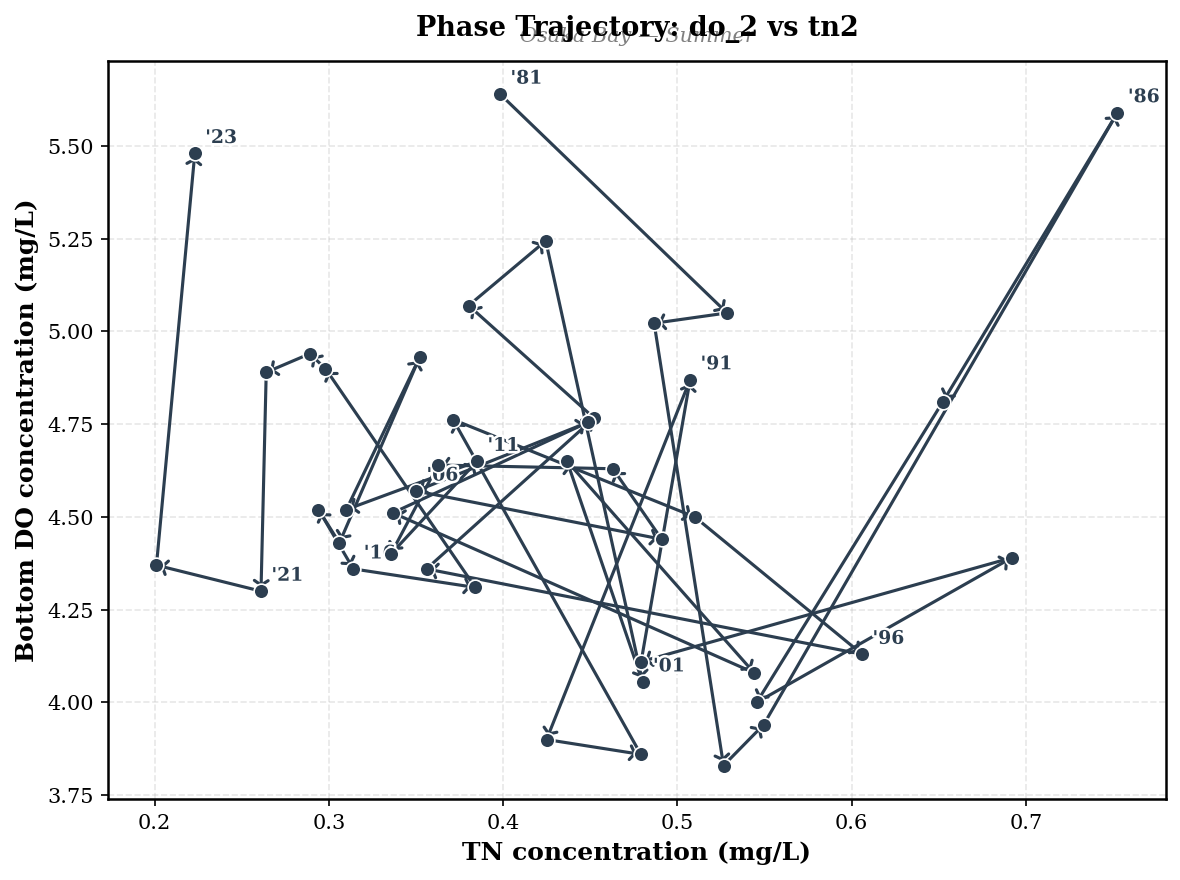

In [5]:
# --- Cell 5: Phase Trajectory Plot ---

plt.rcParams.update({
    'font.family': FONT_FAMILY,
    'font.size': 11,
    'axes.linewidth': 1.2,
})

fig, ax = plt.subplots(figsize=FIGSIZE, dpi=DPI)

x = yearly[X_VAR].values
y = yearly[Y_VAR].values
years = yearly['year'].values

# --- Draw arrows between consecutive points ---
for i in range(len(x) - 1):
    dx = x[i+1] - x[i]
    dy = y[i+1] - y[i]
    ax.annotate(
        '',
        xy=(x[i+1], y[i+1]),          # arrow tip
        xytext=(x[i], y[i]),           # arrow tail
        arrowprops=dict(
            arrowstyle='->,head_width=0.3,head_length=0.2',
            color=ARROW_COLOR,
            lw=ARROW_WIDTH,
            connectionstyle='arc3,rad=0.0',   # straight line; change rad for curves
        )
    )

# --- Draw data points ---
ax.scatter(x, y, s=MARKER_SIZE, color=MARKER_COLOR, zorder=5, edgecolors='white', linewidths=0.8)

# --- Add year labels ---
for i, yr in enumerate(years):
    if (yr - years[0]) % LABEL_INTERVAL == 0 or i == len(years) - 1:
        label_text = LABEL_FORMAT.format(yr % 100)
        ax.annotate(
            label_text,
            (x[i], y[i]),
            textcoords='offset points',
            xytext=LABEL_OFFSET,
            fontsize=LABEL_FONTSIZE,
            fontweight='bold',
            color=MARKER_COLOR,
            path_effects=[
                pe.withStroke(linewidth=2.5, foreground='white')  # white outline for readability
            ]
        )

# --- Axis formatting ---
ax.set_xlabel(X_LABEL, fontsize=12, fontweight='bold')
ax.set_ylabel(Y_LABEL, fontsize=12, fontweight='bold')
ax.set_title(TITLE, fontsize=13, fontweight='bold', pad=12)
ax.text(0.5, 1.02, SUBTITLE, transform=ax.transAxes,
        ha='center', va='bottom', fontsize=10, color='gray', style='italic')

ax.grid(True, alpha=GRID_ALPHA, linestyle='--')
ax.tick_params(axis='both', which='major', labelsize=10)

# Optional: set axis limits manually
# ax.set_xlim(0, None)
# ax.set_ylim(0, None)

fig.tight_layout()

# --- Save ---
if SAVE_FIGURE:
    fig.savefig(SAVE_PATH, dpi=300, bbox_inches='tight', facecolor='white')
    print(f"Figure saved to {SAVE_PATH}")

plt.show()

---
## Variant: Multiple divisions on the same plot
The cell below shows how to overlay multiple regions (divisions) on the same phase plane
with different colors for comparison.

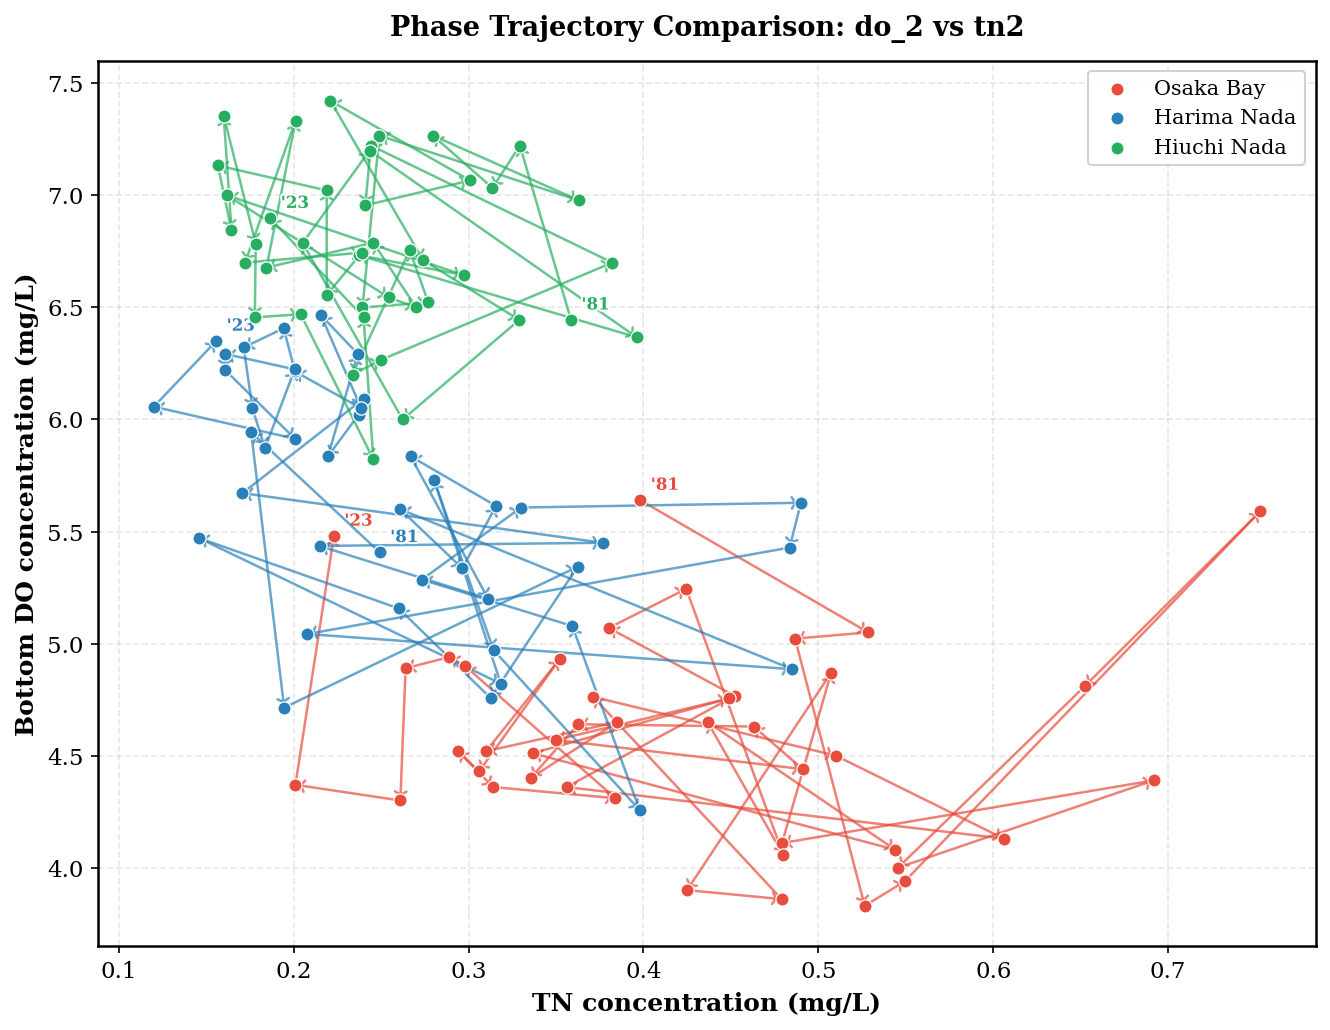

In [6]:
# --- Cell 6: Multi-region Phase Trajectory (optional) ---

# Select which divisions to compare
COMPARE_DIVISIONS = ['Osaka Bay', 'Harima Nada', 'Hiuchi Nada']
COLORS = ['#e74c3c', '#2980b9', '#27ae60']  # Red, Blue, Green

fig, ax = plt.subplots(figsize=(9, 7), dpi=DPI)

for div, color in zip(COMPARE_DIVISIONS, COLORS):
    # Filter
    sub = df.copy()
    sub = sub[sub['division'] == div]
    if FILTER_SEASON is not None:
        sub = sub[sub['season'] == FILTER_SEASON]
    if FILTER_SAISUIPOIN is not None:
        sub = sub[sub['saisuipoin'] == FILTER_SAISUIPOIN]
    sub = sub[(sub['year'] >= YEAR_RANGE[0]) & (sub['year'] <= YEAR_RANGE[1])]
    sub[X_VAR] = pd.to_numeric(sub[X_VAR], errors='coerce')
    sub[Y_VAR] = pd.to_numeric(sub[Y_VAR], errors='coerce')
    sub = sub[(sub[X_VAR] > 0) & (sub[Y_VAR] > 0)]
    
    yearly_sub = sub.groupby('year')[[X_VAR, Y_VAR]].agg(AGG_FUNC).reset_index()
    yearly_sub = yearly_sub.sort_values('year').reset_index(drop=True)
    
    xs = yearly_sub[X_VAR].values
    ys = yearly_sub[Y_VAR].values
    yrs = yearly_sub['year'].values
    
    # Arrows
    for i in range(len(xs) - 1):
        ax.annotate(
            '',
            xy=(xs[i+1], ys[i+1]),
            xytext=(xs[i], ys[i]),
            arrowprops=dict(
                arrowstyle='->,head_width=0.25,head_length=0.15',
                color=color, lw=1.2, alpha=0.7,
            )
        )
    
    # Points
    ax.scatter(xs, ys, s=40, color=color, zorder=5,
               edgecolors='white', linewidths=0.6, label=div)
    
    # Labels (first and last year only for multi-region)
    for idx in [0, -1]:
        label_text = LABEL_FORMAT.format(yrs[idx] % 100)
        ax.annotate(
            label_text, (xs[idx], ys[idx]),
            textcoords='offset points', xytext=(5, 5),
            fontsize=8, fontweight='bold', color=color,
            path_effects=[pe.withStroke(linewidth=2, foreground='white')]
        )

ax.set_xlabel(X_LABEL, fontsize=12, fontweight='bold')
ax.set_ylabel(Y_LABEL, fontsize=12, fontweight='bold')
ax.set_title(f'Phase Trajectory Comparison: {Y_VAR} vs {X_VAR}',
             fontsize=13, fontweight='bold', pad=12)
ax.legend(loc='best', fontsize=10, framealpha=0.9)
ax.grid(True, alpha=GRID_ALPHA, linestyle='--')
fig.tight_layout()
plt.show()

---
## Variant: 5-year averaged phase trajectory
When yearly data is noisy, you can smooth the trajectory by averaging over
multi-year windows (e.g. 5-year bins like the reference figure).

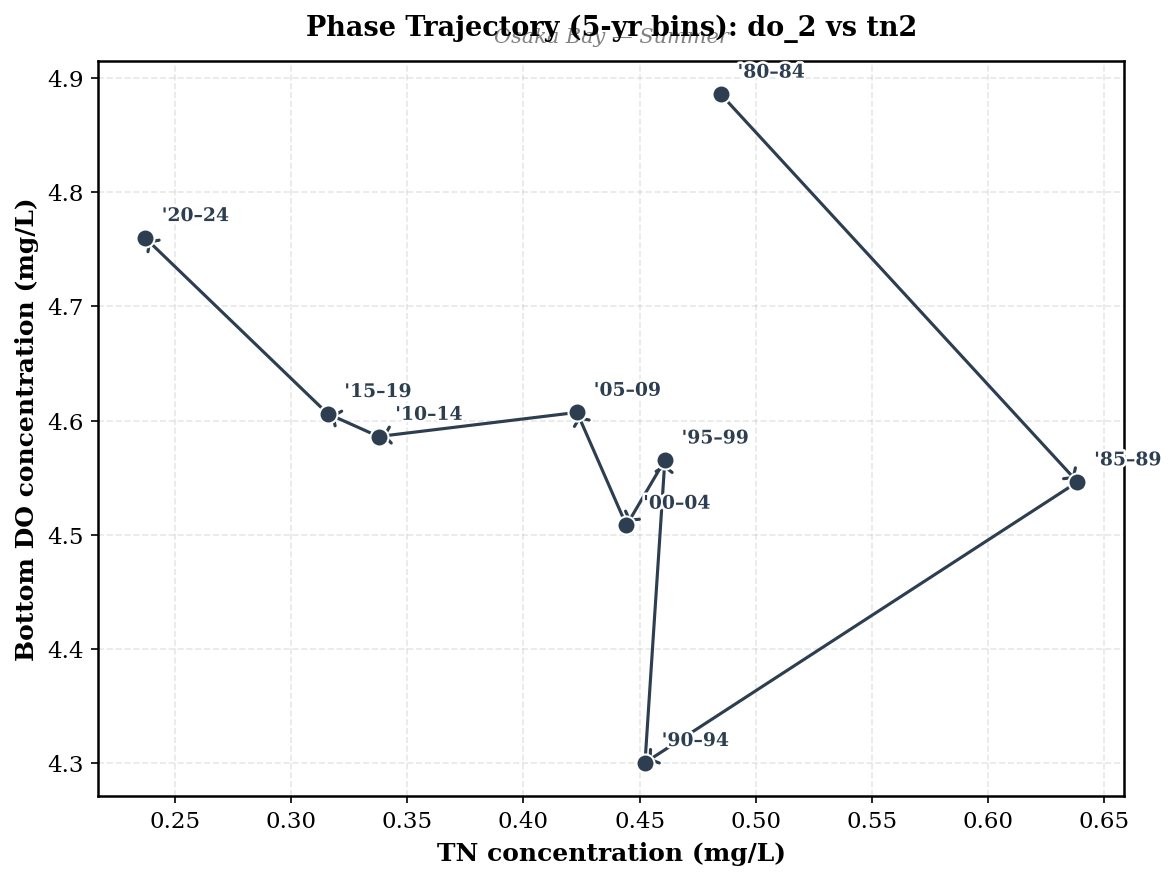

In [7]:
# --- Cell 7: 5-year binned Phase Trajectory ---

BIN_SIZE = 5  # years per bin

# Use the yearly data from Cell 4
yearly_binned = yearly.copy()
yearly_binned['year_bin'] = (yearly_binned['year'] // BIN_SIZE) * BIN_SIZE
binned = yearly_binned.groupby('year_bin')[[X_VAR, Y_VAR]].agg(AGG_FUNC).reset_index()
binned = binned.sort_values('year_bin').reset_index(drop=True)

fig, ax = plt.subplots(figsize=FIGSIZE, dpi=DPI)

xb = binned[X_VAR].values
yb = binned[Y_VAR].values
year_bins = binned['year_bin'].values

# Arrows
for i in range(len(xb) - 1):
    ax.annotate(
        '',
        xy=(xb[i+1], yb[i+1]),
        xytext=(xb[i], yb[i]),
        arrowprops=dict(
            arrowstyle='->,head_width=0.35,head_length=0.25',
            color=ARROW_COLOR, lw=ARROW_WIDTH,
        )
    )

# Points
ax.scatter(xb, yb, s=MARKER_SIZE * 1.5, color=MARKER_COLOR,
           zorder=5, edgecolors='white', linewidths=1)

# Labels (all bins)
for i, yr_bin in enumerate(year_bins):
    label_text = f"'{yr_bin % 100:02d}–{(yr_bin + BIN_SIZE - 1) % 100:02d}"
    ax.annotate(
        label_text, (xb[i], yb[i]),
        textcoords='offset points', xytext=(8, 8),
        fontsize=LABEL_FONTSIZE, fontweight='bold', color=MARKER_COLOR,
        path_effects=[pe.withStroke(linewidth=2.5, foreground='white')]
    )

ax.set_xlabel(X_LABEL, fontsize=12, fontweight='bold')
ax.set_ylabel(Y_LABEL, fontsize=12, fontweight='bold')
ax.set_title(f'Phase Trajectory ({BIN_SIZE}-yr bins): {Y_VAR} vs {X_VAR}',
             fontsize=13, fontweight='bold', pad=12)
ax.text(0.5, 1.02, SUBTITLE, transform=ax.transAxes,
        ha='center', va='bottom', fontsize=10, color='gray', style='italic')
ax.grid(True, alpha=GRID_ALPHA, linestyle='--')
fig.tight_layout()
plt.show()

---
## Notes on customization

### Available numeric variables in the dataset
| Column | Description |
|--------|-------------|
| `do_2` | Dissolved Oxygen (mg/L) — cleaned |
| `tn2` | Total Nitrogen (mg/L) |
| `tp2` | Total Phosphorus (mg/L) |
| `cod2` | Chemical Oxygen Demand (mg/L) |
| `chloroph_1` | Chlorophyll-a (μg/L) |
| `nh4n2` | NH₄-N (mg/L) |
| `no2n2` | NO₂-N (mg/L) |
| `no3n2` | NO₃-N (mg/L) |
| `po4p2` | PO₄-P (mg/L) |
| `salt2` | Salinity (PSU) |
| `ph2` | pH |

### Available divisions
Check `df['division'].unique()` for the full list — includes Osaka Bay, Harima Nada,
Bisan Seto, Hiuchi Nada, Suo Nada, Bungo Channel, etc.

### Arrow customization
- `connectionstyle='arc3,rad=0.1'` — adds a slight curve to arrows
- `arrowstyle='-|>,head_width=0.4'` — different arrowhead style
- Increase `ARROW_WIDTH` for bolder lines